# ESE5023 Assignment 4

In [1]:
# Import modules
import os

import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon
%matplotlib inline

# Folder for the figures used in the report
os.makedirs("figs", exist_ok=True)

# Coastline and land polygons from Natural Earth 110m. Both are stored as one array
# with a NaN row between the segments. cartopy would project and draw these for us,
# but its pyproj DLL is blocked by the application control policy on this laptop, so
# the projection is coded by hand below.
try:
    coast = np.load("coastlines.npz")["coast"]
    land = np.load("land.npz")["land"]
except FileNotFoundError:
    coast = None
    land = None

# Robinson projection table (X0, Y0) for the 5-degree latitude bands
_lat_tab = np.array([0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55,
                     60, 65, 70, 75, 80, 85, 90.])
_X0 = np.array([1.0000, 0.9986, 0.9954, 0.9900, 0.9822, 0.9730, 0.9600,
                0.9427, 0.9216, 0.8962, 0.8679, 0.8350, 0.7986, 0.7597,
                0.7186, 0.6732, 0.6213, 0.5722, 0.0000])
_Y0 = np.array([0.0000, 0.0620, 0.1240, 0.1860, 0.2480, 0.3100, 0.3720,
                0.4340, 0.4958, 0.5571, 0.6176, 0.6769, 0.7346, 0.7903,
                0.8435, 0.8936, 0.9394, 0.9761, 1.0000])


def robinson(lon, lat, clon=180.0):
    # Forward Robinson projection for points, returns x, y in normalized units
    lon = np.atleast_1d(np.asarray(lon, dtype=float))
    lat = np.atleast_1d(np.asarray(lat, dtype=float))
    lam = np.radians(((lon - clon + 180) % 360) - 180)
    phi = np.abs(lat)
    x = 0.8487 * lam * np.interp(phi, _lat_tab, _X0)
    y = np.broadcast_to(1.3523 * np.interp(phi, _lat_tab, _Y0) * np.sign(lat),
                        lam.shape)
    return x.copy(), y.copy()


def robinson_point(lon, lat, clon=180.0):
    # Same projection for a single point, returned as two plain floats so that
    # matplotlib can take them directly as coordinates
    x, y = robinson(lon, lat, clon)
    return float(x[0]), float(y[0])


def robinson_ring(lon, lat, clon=180.0, clip=88.0):
    # Projection for a polygon ring. The longitude is unwrapped first so that a ring
    # crossing the map edge stays in one piece, and the latitude is capped at 88
    # degrees because X0 goes to zero at the poles.
    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)
    lam = np.unwrap(((lon - clon + 180) % 360) - 180, period=360)
    phi = np.minimum(np.abs(lat), clip)
    x = 0.8487 * np.radians(lam) * np.interp(phi, _lat_tab, _X0)
    y = 1.3523 * np.interp(phi, _lat_tab, _Y0) * np.sign(lat)
    return x, y


def scalar(value):
    # Turn a 0-d xarray or a one-element array into a plain Python float
    return float(np.asarray(value).reshape(-1)[0])


def split_segments(array):
    # Split the coastline and land arrays at the NaN rows
    segments = np.split(array, np.where(np.isnan(array[:, 0]))[0])
    return [s[~np.isnan(s[:, 0])] for s in segments]


def map_outline(clon=180.0):
    # Outline of the Robinson map in projected units, used as the ocean and as the
    # clipping path for the land and the coastlines
    phi = np.linspace(-90, 90, 361)
    _, y = robinson(np.zeros_like(phi), phi, clon)
    x = 0.8487 * np.pi * np.interp(np.abs(phi), _lat_tab, _X0)
    return np.column_stack([np.concatenate([x, -x[::-1]]),
                            np.concatenate([y, y[::-1]])])


def draw_land(ax, outline, clon=180.0, color="#e6dcc3"):
    # Fill the land polygons, clipped to the oval outline of the map
    if land is None:
        return
    for seg in split_segments(land):
        if len(seg) < 3:
            continue
        if seg[:, 1].min() < -85:
            # Antarctica is a ring around the pole and cannot be closed as a
            # polygon on this projection, so it is filled as a band between its
            # coastline and the bottom edge of the map, in an ice tone
            pts = seg[seg[:, 1] > -80]
            x, y = robinson_ring(pts[:, 0], pts[:, 1], clon)
            order = np.argsort(x)
            band = ax.fill_between(x[order], y[order], -1.45, color="#f4f8fb",
                                   linewidth=0, zorder=1)
            band.set_clip_path(outline)
            continue
        x, y = robinson_ring(seg[:, 0], seg[:, 1], clon)
        poly = Polygon(np.column_stack([x, y]), closed=True, facecolor=color,
                       edgecolor="none", zorder=1)
        poly.set_clip_path(outline)
        ax.add_patch(poly)


def draw_coast(ax, outline=None, clon=180.0, color="0.45", lw=0.4):
    # Coastlines projected by hand; they are clipped when an outline is given
    if coast is None:
        return
    for seg in split_segments(coast):
        if len(seg) < 2:
            continue
        x, y = robinson_ring(seg[:, 0], seg[:, 1], clon)
        line, = ax.plot(x, y, color=color, linewidth=lw, zorder=2)
        if outline is not None:
            line.set_clip_path(outline)


def draw_grid(ax, clon=180.0, color="0.88", lw=0.4):
    # Parallels every 30 degrees and meridians every 60 degrees
    for la in [-60, -30, 0, 30, 60]:
        x, y = robinson(np.linspace(-180, 180, 181), la, clon)
        ax.plot(x, y, color=color, linewidth=lw, zorder=0)
    for lo in range(-120, 180, 60):
        x, y = robinson(np.full(51, lo), np.linspace(-85, 85, 51), clon)
        ax.plot(x, y, color=color, linewidth=lw, zorder=0)


def label_lon(value, clon=180.0):
    # Longitude label for the map that is centered on clon
    orig = (value + clon) % 360
    if orig in (0, 180):
        return "{:.0f}°".format(orig)
    if orig < 180:
        return "{:.0f}°E".format(orig)
    return "{:.0f}°W".format(360 - orig)


def label_lat(value):
    # Latitude label with the hemisphere
    if value == 0:
        return "0°"
    return "{:.0f}°{}".format(abs(value), "S" if value < 0 else "N")


def robinson_ticks(ax, clon=180.0, meridians=(-120, -60, 0, 60, 120),
                   parallels=(-60, -30, 0, 30, 60)):
    # Ticks placed at the projected meridians and parallels, so that they sit on
    # the graticule instead of on the rectangle border
    ax.set_xticks([robinson_point(m + clon, 0, clon)[0] for m in meridians])
    ax.set_xticklabels([label_lon(m, clon) for m in meridians])
    ax.set_yticks([robinson_point(0, p, clon)[1] for p in parallels])
    ax.set_yticklabels([label_lat(p) for p in parallels])

## 1. Global Earthquakes

The USGS file `usgs_earthquakes.csv` lists earthquakes recorded in 2014. I use the `mag` column for
magnitude and the `latitude`, `longitude` columns to place the events, then keep the 50 largest events to
reproduce the reference map.

In [2]:
# Read the local catalog and keep the 50 largest events by magnitude
quakes = pd.read_csv("usgs_earthquakes.csv")[["mag", "latitude", "longitude", "place"]]
top50 = quakes.sort_values(by="mag", ascending=False).head(50).reset_index(drop=True)

print("events in catalog:", len(quakes))
print("top 50 magnitude range:", top50.mag.min(), "-", top50.mag.max())
top50.head(10)

events in catalog: 120108
top 50 magnitude range: 6.5 - 8.2


,mag,latitude,longitude,place
0,8.2,-19.6097,-70.7691,"94km NW of Iquique, Chile"
1,7.9,51.8486,178.7352,"19km SE of Little Sitkin Island, Alaska"
2,7.7,-20.5709,-70.4931,"53km SW of Iquique, Chile"
3,7.6,-11.2701,162.1481,"93km SSE of Kirakira, Solomon Islands"
4,7.5,-6.7547,155.0241,"70km SW of Panguna, Papua New Guinea"
5,7.4,-11.4633,162.0511,"112km S of Kirakira, Solomon Islands"
6,7.3,12.5262,-88.1225,"74km S of Intipuca, El Salvador"
7,7.2,17.3970,-100.9723,"33km ESE of Petatlan, Mexico"
8,7.1,1.8929,126.5217,"154km NW of Kota Ternate, Indonesia"
9,7.1,-19.6903,-177.7587,"144km NE of Ndoi Island, Fiji"


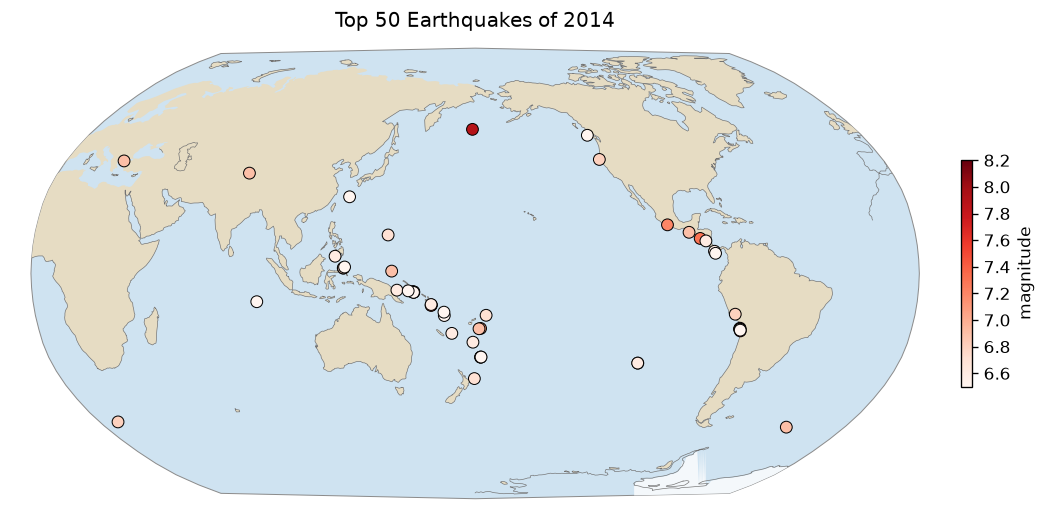

In [3]:
fig, ax = plt.subplots(figsize=(12, 7), dpi=120)

# Ocean, plus the oval outline of the Robinson map; the land is filled in light brown
outline_path = map_outline()
outline = Polygon(outline_path, closed=True, facecolor="#cfe3f1",
                  edgecolor="0.55", linewidth=0.6, zorder=0)
ax.add_patch(outline)
draw_land(ax, outline)
draw_coast(ax, outline)

# Project the events, then color the points by magnitude
sx, sy = robinson(top50.longitude.values, top50.latitude.values)
sc = ax.scatter(sx, sy, c=top50.mag, s=50, cmap="Reds", vmin=6.5, vmax=8.2,
                edgecolors="k", linewidths=0.6, zorder=3)

# Colorbar and title, as in the reference figure
cbar = fig.colorbar(sc, ax=ax, shrink=0.35, pad=0.02, label="magnitude")
cbar.set_ticks([round(v, 1) for v in np.arange(6.6, 8.21, 0.2)])
ax.set_title("Top 50 Earthquakes of 2014")
ax.set_aspect("equal")
ax.set_xlim(-2.78, 2.78)
ax.set_ylim(-1.42, 1.42)
ax.axis("off")

fig.savefig("figs/fig4_1.png", bbox_inches="tight")
plt.show()

The catalog contains 120,108 events recorded in 2014. After sorting by magnitude and keeping the first
50, the magnitudes run from 6.5 to 8.2. The map follows the reference figure: a Robinson projection
centered on the Pacific with the land in light brown and the ocean in light blue, no frame around the map,
the events colored from white to dark red by magnitude with a black outline, and a colorbar on the right.
Most of the large events sit along the Pacific Ring of Fire: the Aleutian arc, Japan and the Mariana
Islands, Papua New Guinea and the Solomon Islands, Tonga and Fiji, the Central American trench, and the
coast of Chile and Peru. The largest event is M8.2, 94 km NW of Iquique, Chile, followed by M7.9 in the
Aleutian Islands and a second M7.7 event off northern Chile. A few events sit outside the Pacific rim,
for example on the mid-Atlantic Ridge and in the Indian Ocean.

## 2. Explore a netCDF dataset

I reuse the GPCP monthly precipitation product (NASA GSFC, GES DISC `GPCPMON`, version 2.3) from
Assignment 3. The local file `precip.mon.mean.nc` gives monthly precipitation rate in mm/day on a 2.5°
global grid from 1979-01 to 2026-06. I average all months into an annual climatology and plot it once
globally and once over a selected region.

In [4]:
# Open the local GPCP file, no download needed
# time_bnds carries fill values that break the automatic time decoding, so it is dropped
precip_ds = xr.open_dataset("precip.mon.mean.nc", engine="netcdf4",
                            drop_variables=["time_bnds"])

# Missing cells are filled with -9.96921e36, mask them by hand as well
precip = precip_ds["precip"].where(precip_ds["precip"] >= 0)

# Annual climatology: average every month in the file
precip_clim = precip.mean("time")

# Cell area is proportional to cos(lat), use it as the weight for the global mean
weights = np.cos(np.deg2rad(precip_clim.lat))
global_mean = scalar(precip_clim.weighted(weights).mean())

print("global mean:", round(global_mean, 2), "mm/day")
print("grid range:", round(scalar(precip_clim.min()), 2), "-",
      round(scalar(precip_clim.max()), 2), "mm/day")
precip_clim

global mean: 2.69 mm/day
grid range: 0.01 - 14.23 mm/day


<xarray.DataArray 'precip' (lat: 72, lon: 144)> Size: 41kB
array([[0.3108488 , 0.30495808, 0.30018917, ..., 0.31554067, 0.32758412,
        0.326071  ],
       [0.2052544 , 0.20536523, 0.196204  , ..., 0.21134083, 0.21622294,
        0.21032403],
       [0.17109297, 0.16770007, 0.14844345, ..., 0.1940487 , 0.19290665,
        0.18489678],
       ...,
       [0.54772997, 0.5498562 , 0.5550594 , ..., 0.5415687 , 0.538876  ,
        0.5395282 ],
       [0.50970477, 0.51543635, 0.5165036 , ..., 0.506776  , 0.5113758 ,
        0.51202613],
       [0.5210923 , 0.5255551 , 0.5212296 , ..., 0.5133062 , 0.5166119 ,
        0.51860535]], shape=(72, 144), dtype=float32)
Coordinates:
  * lat      (lat) float32 288B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
  * lon      (lon) float32 576B 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
Attributes:
    long_name:     Average Monthly Rate of Precipitation
    valid_range:   [  0. 100.]
    units:         mm/day
    precision:     32767
    var_desc:      Precipitation
    dataset:       GPCP Version 2.3 Combined Precipitation Dataset
    level_desc:    Surface
    statistic:     Mean
    parent_stat:   Mean
    actual_range:  [ 0.       47.327435]

### 2.1 [10 points] Global map of the annual mean precipitation

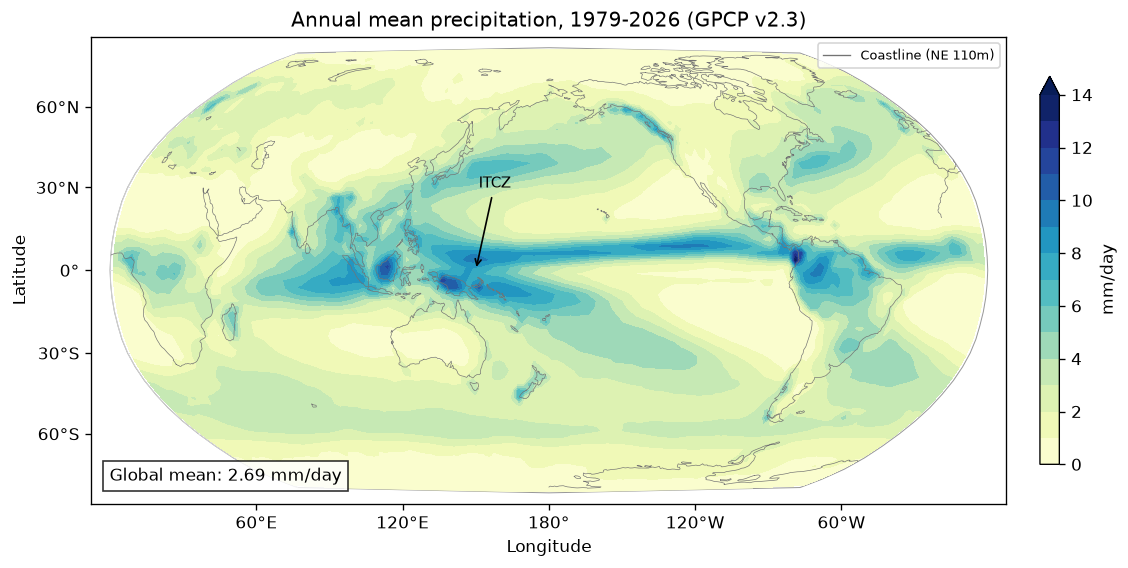

In [5]:
# Project the 2.5-degree grid onto the Robinson map
lon = precip_clim.lon.values
lat = precip_clim.lat.values
LON, LAT = np.meshgrid(lon, lat)
X, Y = robinson(LON, LAT)

fig, ax = plt.subplots(figsize=(12, 7), dpi=120)

levels = np.arange(0, 15, 1)
cf = ax.contourf(X, Y, precip_clim.values, levels=levels,
                 cmap="YlGnBu", extend="max", zorder=1)

# Map outline, graticule and coastlines. The filled field and the coastlines are
# clipped to the outline, because contourf fills the convex hull of the grid and
# would otherwise spill over the edge of the projection
outline_path = map_outline()
outline = Polygon(outline_path, closed=True, facecolor="none",
                  edgecolor="0.6", linewidth=0.6, zorder=0)
ax.add_patch(outline)
cf.set_clip_path(outline)
draw_grid(ax)
draw_coast(ax, outline)
robinson_ticks(ax)

# Mark the intertropical convergence zone over the western Pacific
itcz_x, itcz_y = robinson_point(150, 0)
itcz_tx, itcz_ty = robinson_point(150, 30)
ax.annotate("ITCZ", xy=(itcz_x, itcz_y), xytext=(itcz_tx, itcz_ty),
            arrowprops=dict(arrowstyle="->", color="k"), fontsize=9)

# Text box with the global mean
ax.text(0.02, 0.05, "Global mean: 2.69 mm/day",
        transform=ax.transAxes, bbox=dict(facecolor="white", alpha=0.8))

# Legend entry for the coastline
leg = Line2D([0], [0], color="0.45", linewidth=0.8,
             label="Coastline (NE 110m)")
ax.legend(handles=[leg], loc="upper right", fontsize=8)

fig.colorbar(cf, ax=ax, shrink=0.6, pad=0.03, label="mm/day")
ax.set_title("Annual mean precipitation, 1979-2026 (GPCP v2.3)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.set_xlim(-2.78, 2.78)
ax.set_ylim(-1.42, 1.42)

fig.savefig("figs/fig4_2.png", bbox_inches="tight")
plt.show()

The global map uses the Robinson projection, centered on the Pacific, with a graticule, coastlines,
axis labels and ticks, a colorbar, an annotation and a text box. The area-weighted global mean is
2.69 mm/day. The ITCZ shows up as the dark blue band near the equator, with the strongest rain over the
western Pacific warm pool, the Amazon and the Congo basin; the subtropical belts near 20-30°N/S are dry,
and the high latitudes receive only light rain. Cells with the file fill value are masked before the
average, so they do not contribute to the map.

### 2.2 [10 points] Regional map of the same variable

regional mean: 3.17 mm/day


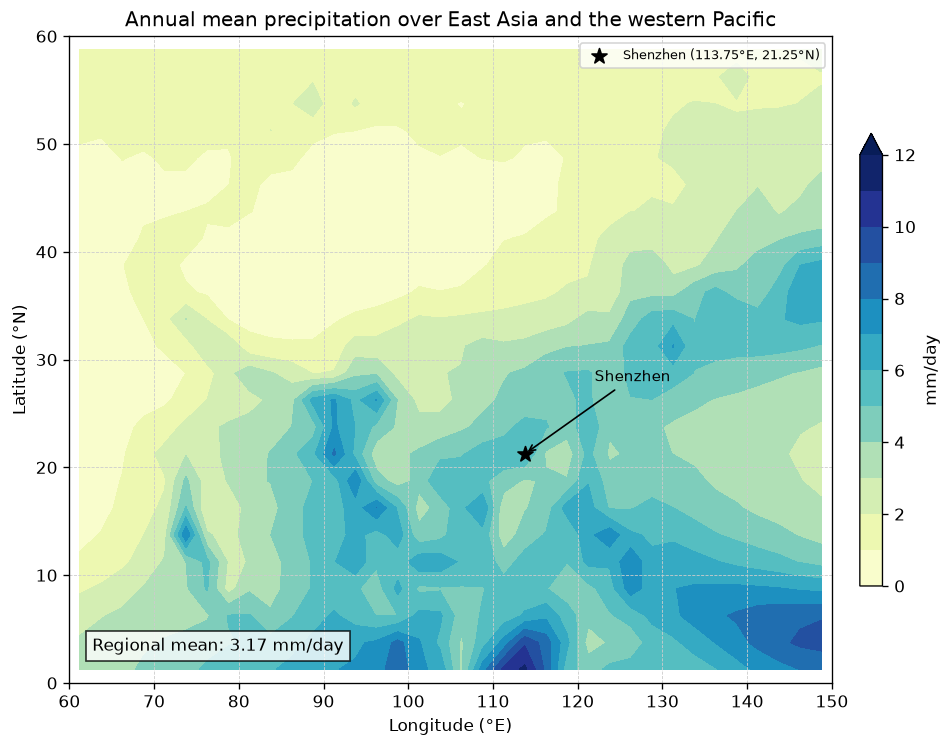

In [6]:
# East Asia and the western Pacific: 60-150E, 0-60N
reg = precip_clim.sel(lat=slice(0, 60), lon=slice(60, 150))
print("regional mean:", round(scalar(reg.mean()), 2), "mm/day")

fig, ax = plt.subplots(figsize=(10, 7), dpi=120)

levels = np.arange(0, 13, 1)
cf = ax.contourf(reg.lon, reg.lat, reg.values, levels=levels,
                 cmap="YlGnBu", extend="max", zorder=1)
draw_coast(ax)

ax.set_xlim(60, 150)
ax.set_ylim(0, 60)
ax.grid(linestyle="--", color="0.8", linewidth=0.5, zorder=0)

# Shenzhen, nearest grid point 21.25N, 113.75E
ax.scatter([113.75], [21.25], marker="*", color="k", s=90, zorder=3,
           label="Shenzhen (113.75°E, 21.25°N)")
ax.annotate("Shenzhen", xy=(113.75, 21.25), xytext=(122, 28),
            arrowprops=dict(arrowstyle="->", color="k"), fontsize=9)

ax.text(0.03, 0.05, "Regional mean: 3.17 mm/day",
        transform=ax.transAxes, bbox=dict(facecolor="white", alpha=0.8))
ax.legend(loc="upper right", fontsize=8)

fig.colorbar(cf, ax=ax, shrink=0.7, pad=0.03, label="mm/day")
ax.set_title("Annual mean precipitation over East Asia and the western Pacific")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

fig.savefig("figs/fig4_3.png", bbox_inches="tight")
plt.show()

The regional panel switches to a plain equirectangular projection over East Asia and the western
Pacific (60-150°E, 0-60°N), so it uses a different projection from the global map. The box mean is
3.17 mm/day, wetter than the global average because it covers the East Asian monsoon region and the
western Pacific warm pool. Rainfall increases from the dry subtropical inland northwest toward the coast
and the open ocean; the star marks Shenzhen (113.75°E, 21.25°N), whose nearest grid point averages
5.96 mm/day over the year.

## Notes

The earthquake CSV was provided with the assignment; the GPCP precipitation file is the same local file
used in Assignment 3. The notebook reads only local files and does not download anything. cartopy is not
used because its pyproj DLL is blocked by the application control policy on my laptop, so the Robinson
projection is coded by hand and the coastlines and land polygons come from the Natural Earth 110m files
stored locally. The plotting follows the Section 07 and Section 08 notebooks. I worked on this assignment
independently.